# Лекция 9. PPO: шаг, который не портит стратегию

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/IlyaChichkanov/Reinforcement-learning/blob/main/09-ppo/lecture/lecture.ipynb)

**Главный вопрос сегодня: можно ли учиться на одном куске несколько раз — и не сломать стратегию?**

На прошлой лекции актор-критик сыграл кусок из $n$ шагов, сделал по нему **один** шаг градиента и больше к нему не возвращался. DQN в это же время доставал каждый переход из буфера десятки раз — и потому тратил меньше шагов в среде. Сегодня научимся так же использовать кусок несколько раз: разберёмся, что при этом ломается, и как это чинит **PPO** (Proximal Policy Optimization) — метод, которым сегодня учат роботов и языковые модели.

Разделы:

1. Что ломается, если пройти по куску несколько раз
2. $\rho$: во сколько раз изменилась вероятность
3. Клиппинг: это и есть PPO
4. Три варианта на лунном модуле
5. Тяга вместо кнопок
6. Итоги

In [1]:
# Ноутбук считается меньше минуты: по умолчанию берутся сохранённые результаты обучения.
TRAIN_LANDER = False      # True — обучить модуль заново: около 3 минут на запуск, в лекции 40 запусков; нужен пакет gymnasium[box2d]
SEEDS = range(10)          # номера запусков
STEPS = 1_000_000         # шагов в среде на один запуск

# Служебные модули: в репозитории лежат рядом, в Google Colab скачиваются заново при каждом запуске.
import pathlib, sys, urllib.request
RAW = "https://raw.githubusercontent.com/IlyaChichkanov/Reinforcement-learning/main"
FILES = ("08-actor-critic/lecture/ac_core.py", "09-ppo/lecture/ppo_core.py", "09-ppo/lecture/ppo_plots.py",
         "09-ppo/lecture/lander_ppo_results.npz")
for file in FILES:
    local = pathlib.Path("../..") / file
    if local.exists():
        sys.path.append(str(local.parent))
    else:
        urllib.request.urlretrieve(f"{RAW}/{file}", pathlib.Path(file).name)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from ppo_core import *            # среда и функции лекции 8 + сбор куска с log π старой стратегии
from ppo_plots import *           # картинки этой лекции
torch.set_num_threads(1)

## 1. Что ломается, если пройти по куску несколько раз

**Главная идея: веса действий посчитаны для той стратегии, которая сыграла кусок; после первого же прохода стратегия другая, и дальше мы учимся по чужим весам.**

Напомним шаг актора-критика из лекции 8: сыграли кусок из $n$ шагов, для каждого шага посчитали вес действия — преимущество $A_t = G_t - V_w(s_t)$, — и сделали **один** шаг градиента. Кусок после этого выбрасывается, хотя стоил нам $n$ шагов в среде.

Соблазн очевидный: пройти по тому же куску ещё несколько раз. Но у веса $A_t$ есть хозяин: он посчитан для стратегии, которая кусок сыграла. После первого прохода стратегия уже другая — а веса остались прежними.

**Вопрос 1.** Берём стратегию, обученную на прошлой лекции, играем ею кусок (225 шагов) и делаем по нему не один шаг градиента, а 10 — по тем же данным и с теми же весами действий. Что станет с вероятностями сыгранных действий?

- **A.** Почти ничего: шаг градиента маленький, 10 шагов тоже мало что меняют.
- **B.** Вероятности части действий изменятся в разы.
- **C.** Все вероятности вырастут: мы же 10 раз поощряли эти действия.

один проход  шагов в куске 225, ρ от 0.97 до 1.11, дальше чем в 1.2 раза ушли 0 % шагов
10 проходов  шагов в куске 225, ρ от 0.60 до 2.60, дальше чем в 1.2 раза ушли 28 % шагов


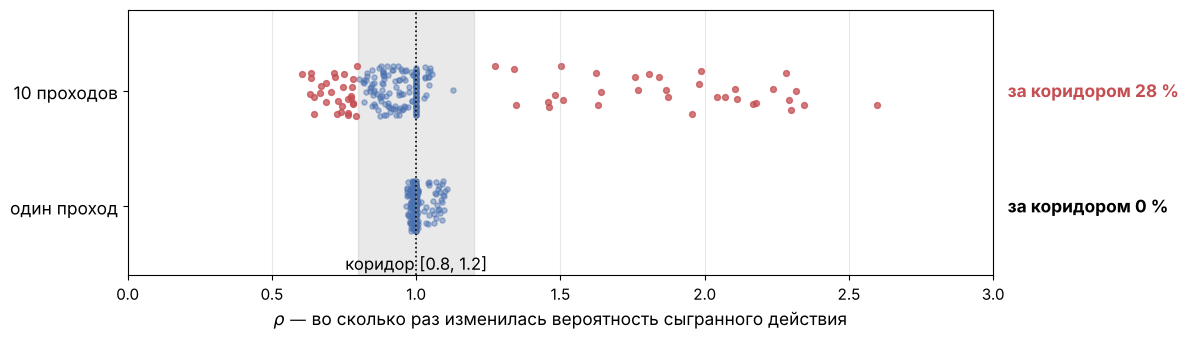

In [3]:
# один кусок, сыгранный стратегией прошлой лекции; ρ — во сколько раз изменилась вероятность сыгранного действия
rho = {"один проход": measure_rho(epochs=1), "10 проходов": measure_rho(epochs=10)}
for name, values in rho.items():
    print(f"{name:12s} шагов в куске {len(values)}, ρ от {values.min():.2f} до {values.max():.2f},"
          f" дальше чем в 1.2 раза ушли {100 * np.mean((values < 0.8) | (values > 1.2)):.0f} % шагов")
plot_rho(rho)
plt.show()

Ответ **B**. После одного прохода вероятности почти не меняются: $\rho$ от 0.97 до 1.11, дальше чем в 1.2 раза не ушёл ни один шаг. После десяти проходов $\rho$ доходит до 2.6 и падает до 0.60: у 28 % шагов вероятность изменилась больше чем в 1.2 раза.

Вариант **C** неверен: вероятности в сумме дают единицу, поэтому вырасти у всех они не могут — у действий с отрицательным весом они падают.

**Почему это плохо.** Вес $A_t$ говорит, насколько действие было лучше обычного **для той стратегии**, которая сыграла кусок. Если новая стратегия выбирает в этих состояниях уже другое, старые веса описывают не её, и шаги градиента делаются вслепую.

**Одной строкой:** проходы по одному куску дают больше обучения из тех же данных, но уводят стратегию от той, для которой считались веса.

## 2. $\rho$: во сколько раз изменилась вероятность

**Главная идея: насколько новая стратегия отличается от старой, видно по одному числу на шаг — отношению вероятностей сыгранного действия.**

$$\rho_t \;=\; \frac{\pi_\theta(a_t \mid s_t)}{\pi_{\text{старая}}(a_t \mid s_t)}$$

$\pi_{\text{старая}}$ — та стратегия, которая сыграла кусок; её $\log \pi$ мы запоминаем при сборе куска. Если $\rho_t = 1$, вероятность этого действия не изменилась; $\rho_t = 1.4$ — стало в 1.4 раза вероятнее; $\rho_t = 0.5$ — вдвое реже.

Теперь вес действия записывают через $\rho$:

$$\text{слагаемое} = \rho_t \, A_t \qquad \text{вместо} \qquad A_t \log \pi_\theta(a_t \mid s_t)$$

Производная $\rho_t$ по $\theta$ равна $\rho_t \cdot \nabla_\theta \log \pi_\theta(a_t \mid s_t)$, поэтому при $\rho_t = 1$ шаг получается ровно тот же, что в лекции 8. А когда стратегия уходит, $\rho_t$ это показывает.

**Вопрос 2.** В каком-то состоянии куска старая стратегия давала сыгранному действию вероятность 0.10, а новая даёт 0.14. Чему равно $\rho_t$ и что это значит?

- **A.** $\rho_t = 0.04$ — вероятность выросла на 4 процентных пункта.
- **B.** $\rho_t = 1.4$ — действие стало в 1.4 раза вероятнее, чем было.
- **C.** $\rho_t = 1.4$ — действие стало в 1.4 раза лучше.

Ответ **B**: $\rho_t = 0.14 / 0.10 = 1.4$ — вероятность сыгранного действия выросла в 1.4 раза. Про то, хорошее действие или плохое, $\rho_t$ не говорит ничего: это дело веса $A_t$.

**Так делал TRPO** (2015), предшественник PPO: он прямо ограничивал, насколько новая стратегия может отличаться от старой, и на каждом шаге решал задачу с этим ограничением — честно, но тяжело считать. PPO (2017) добивается того же одной строкой.

**Одной строкой:** $\rho_t$ — мерка того, насколько стратегия ушла от той, что собрала кусок.

## 3. Клиппинг: это и есть PPO

**Главная идея: если $\rho_t$ вышел за коридор $[1-\varepsilon,\ 1+\varepsilon]$, слагаемое перестаёт расти — градиент в эту сторону исчезает.**

$$\text{слагаемое PPO} \;=\; \min\Big(\rho_t A_t,\ \ \mathrm{clip}(\rho_t,\ 1-\varepsilon,\ 1+\varepsilon)\, A_t\Big), \qquad \varepsilon = 0.2$$

$\mathrm{clip}$ зажимает $\rho_t$ в коридор. Минимум из двух слагаемых нужен, чтобы ограничение работало в обе стороны: посмотрим на картинку.

**Вопрос 3.** Действие оказалось лучше обычного ($A_t > 0$), и после нескольких проходов $\rho_t$ дошёл до 1.5 — за коридор $[0.8,\ 1.2]$. Что сделает следующий шаг градиента с вероятностью этого действия?

- **A.** Поднимет ещё сильнее: ведь действие хорошее, а $\rho_t$ большой.
- **B.** Не тронет: слагаемое уже не растёт с ростом $\rho_t$, градиента по нему нет.
- **C.** Вернёт вероятность обратно в коридор.

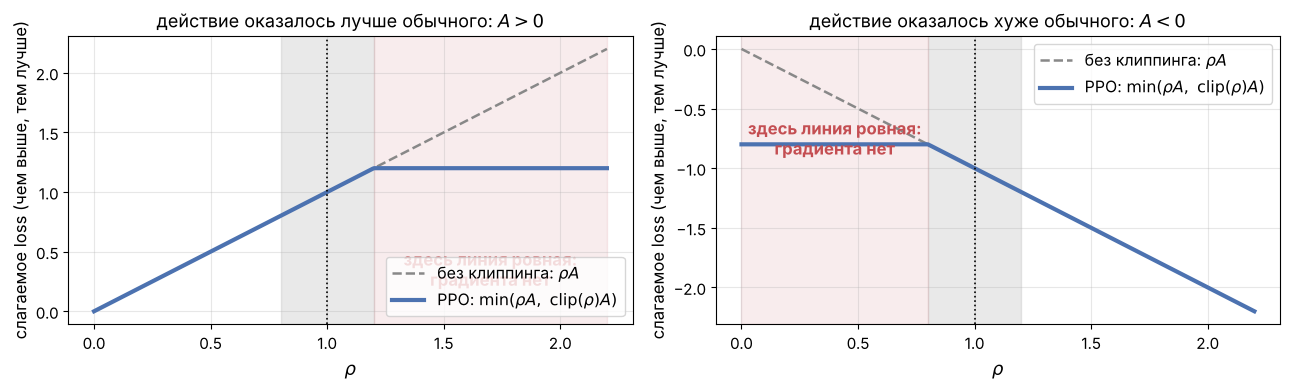

In [4]:
draw_clip(eps=0.2)
plt.show()

Ответ **B**. При $A_t > 0$ и $\rho_t > 1 + \varepsilon$ берётся обрезанное слагаемое — на картинке линия идёт ровно, поэтому производная равна нулю: поднимать вероятность дальше не за что. Обратно в коридор клиппинг не тянет (вариант **C**): он не наказывает за уход, а просто перестаёт за него платить. А если действие оказалось хуже обычного ($A_t < 0$), ровная часть стоит слева: нельзя бесконечно давить вероятность вниз.

Проверим, держит ли клиппинг стратегию на том же куске, что в разделе 1:

один проход                    ρ от 0.97 до 1.11, дальше чем в 1.2 раза ушли 0 % шагов
10 проходов                    ρ от 0.60 до 2.60, дальше чем в 1.2 раза ушли 28 % шагов
PPO: 10 проходов с клиппингом  ρ от 0.89 до 1.22, дальше чем в 1.2 раза ушли 1 % шагов


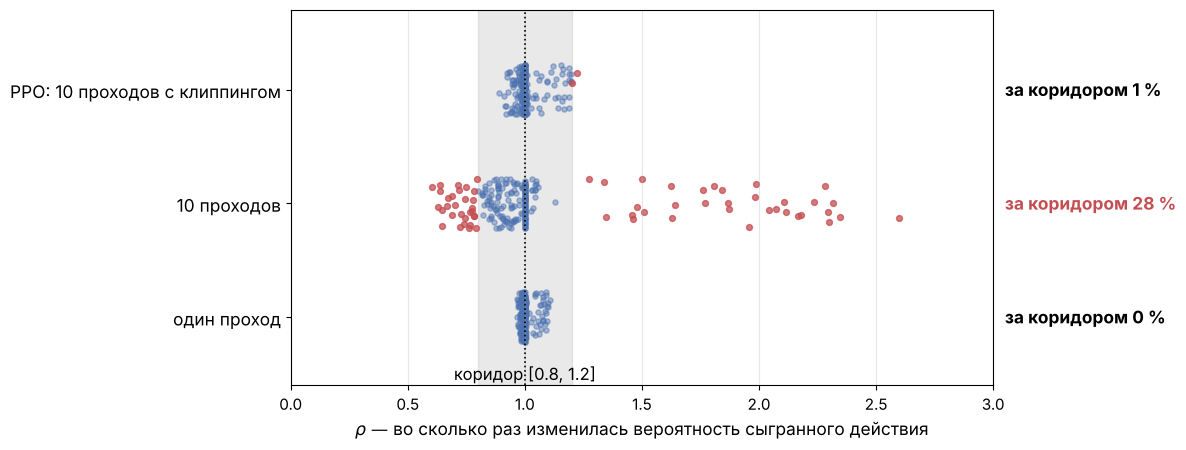

In [5]:
rho["PPO: 10 проходов с клиппингом"] = measure_rho(epochs=10, clip=True)
for name, values in rho.items():
    print(f"{name:30s} ρ от {values.min():.2f} до {values.max():.2f},"
          f" дальше чем в 1.2 раза ушли {100 * np.mean((values < 0.8) | (values > 1.2)):.0f} % шагов")
plot_rho(rho)
plt.show()

С клиппингом те же 10 проходов уводят стратегию заметно меньше: за коридор вышли 1 % шагов против 28 % без него, а наибольший $\rho$ — 1.2 вместо 2.6.

Весь PPO — это три изменения в коде актора-критика: запомнить $\log \pi$ при сборе куска, считать $\rho_t$ и обрезать его, пройти по куску несколько раз. Они помечены `# ← новое`.

In [6]:
def train(seed, steps=STEPS, n=2048, epochs=10, eps=0.2, clip=True):
    # кусок играется один раз, потом по нему делается epochs проходов; clip=False — то же, но без обрезки ρ
    rng, env = np.random.default_rng(seed), make_lander()
    actor, critic = make_net(4, seed), make_net(1, seed + 1000)
    opt = torch.optim.Adam([{"params": actor.parameters(), "lr": 0.0003},
                            {"params": critic.parameters(), "lr": 0.001}])
    played, total, history = 0, 0.0, []
    s, _ = env.reset(seed=seed * 10_000)
    while played < steps:
        S, A, R, logp_old, s, terminated, truncated = collect(actor, env, s, rng, n)   # ← новое: запоминаем log π
        tail = 0.0 if terminated else critic(torch.as_tensor(s)).item()
        G = torch.as_tensor(returns_to_go(R, tail=tail), dtype=torch.float32)
        S, A, logp_old = torch.as_tensor(S), torch.as_tensor(A), torch.as_tensor(logp_old)
        advantage = (G - critic(S).squeeze(1)).detach()                 # вес действия, как в лекции 8
        for _ in range(epochs):                                         # ← новое: несколько проходов по куску
            ratio = torch.exp(log_probs_of(actor, S, A) - logp_old)     # ← новое: ρ — во сколько раз изменилась π
            kept = (torch.min(ratio * advantage, ratio.clamp(1 - eps, 1 + eps) * advantage) if clip
                    else ratio * advantage)                             # ← новое: обрезаем ρ
            loss = -kept.mean() + ((G - critic(S).squeeze(1)) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        played += len(R); total += R.sum()
        if terminated or truncated:
            history.append((played, total)); total = 0.0
            s, _ = env.reset(seed=seed * 10_000 + len(history))
    return np.array(history), actor, critic

**Одной строкой:** клиппинг убирает награду за уход далеко от старой стратегии — поэтому по куску можно пройти много раз.

## 4. Три варианта на лунном модуле

Сравним три варианта одной и той же функции: они отличаются ровно двумя настройками — сколько проходов по куску и обрезаем ли $\rho$.

| вариант | `epochs` | `clip` |
|---|---|---|
| один проход (как в лекции 8) | 1 | нет |
| 10 проходов, без клиппинга | 10 | нет |
| PPO: 10 проходов с клиппингом | 10 | да |

**Вопрос 4.** Какой из трёх вариантов за миллион шагов в среде подойдёт ближе всего к посадке (к 200)?

- **A.** Один проход: веса честные, стратегия не уезжает.
- **B.** 10 проходов без клиппинга: обучения из тех же данных больше всего.
- **C.** 10 проходов с клиппингом.

один проход
    среднее последних 100 эпизодов: -31; по запускам: -48 -46 -44 -41 -33 -28 -25 -24 -19 -2; не меньше 200 — в 0 из 10
    до среднего 200 дошли 0 из 10 запусков


10 проходов, без клиппинга
    среднее последних 100 эпизодов: 26; по запускам: -52 -22 -19 -13 4 24 28 56 91 167; не меньше 200 — в 0 из 10
    до среднего 200 дошли 0 из 10 запусков
PPO: 10 проходов с клиппингом
    среднее последних 100 эпизодов: 173; по запускам: 136 136 139 146 163 186 193 202 209 220; не меньше 200 — в 3 из 10
    до среднего 200 дошли 5 из 10 запусков, шагов в среде, тыс.: 226 237 460 530 714


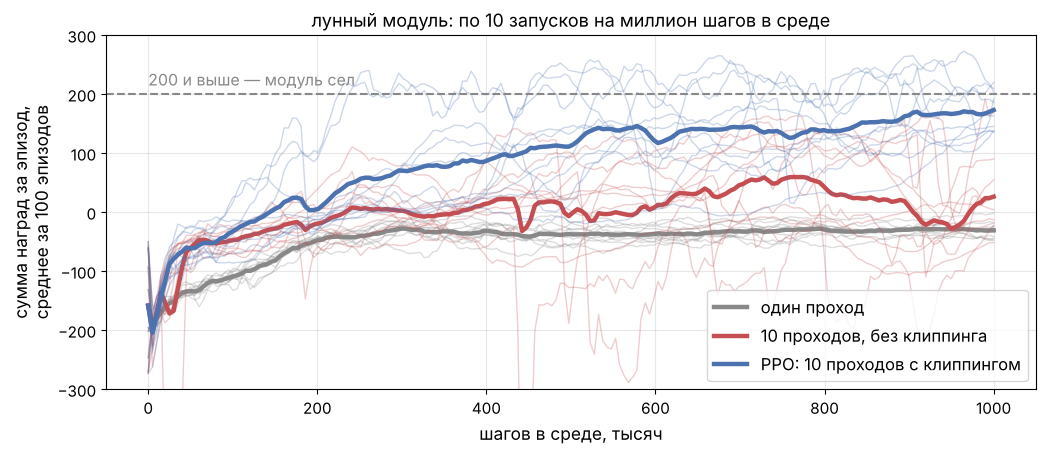

In [7]:
runs = {}
for name, kind, settings in (("один проход", "plain1", dict(epochs=1, clip=False)),
                             ("10 проходов, без клиппинга", "plain10", dict(epochs=10, clip=False)),
                             ("PPO: 10 проходов с клиппингом", "ppo", dict(epochs=10, clip=True))):
    runs[name] = [train(seed, **settings)[0] for seed in SEEDS] if TRAIN_LANDER else load_runs(kind)
    print_runs(name, runs[name])
plot_lander_steps(runs, title="лунный модуль: по 10 запусков на миллион шагов в среде")
plt.show()

Ответ **C**. Среднее последних 100 эпизодов: −31 у одного прохода, 26 у десяти проходов без клиппинга и 173 у PPO; до среднего 200 дошли 0, 0 и 5 запусков из 10 (PPO — за 226–714 тысяч шагов).

**Почему так выходит.** Один проход не использует кусок до конца: данных мало, обучение медленное. Десять проходов без клиппинга дают больше градиентных шагов, но после первых же из них веса перестают описывать текущую стратегию — часть шагов уходит в никуда, и запуски расходятся (от −52 до 167). С клиппингом лишние проходы безопасны: стратегия остаётся рядом с той, что собрала кусок.

Прямо сравнивать эти числа с актором-критиком прошлой лекции нельзя: там были другие настройки (кусок 128 шагов, шаг обучения 0.0007). Что всё же стоит заметить: у PPO запуски держатся кучнее — 136–220 против 61–215 в лекции 8.

**Одной строкой:** несколько проходов по куску помогают только вместе с клиппингом; без него лишние проходы уводят стратегию и обучение буксует.

## 5. Тяга вместо кнопок

**Главная идея: чтобы перейти к действиям-числам, в PPO меняются только выход сети и способ посчитать $\log \pi$.**

До сих пор модуль управлялся четырьмя кнопками. У того же модуля есть вариант, где действие — **два числа** от −1 до 1: насколько открыт главный двигатель и насколько боковой. Сеть теперь выдаёт не вероятности кнопок, а **среднее** $\mu_\theta(s)$ — два числа; к ним добавляется **разброс** $\sigma$ (ещё два числа, которые тоже учатся). Действие берётся случайно из нормального распределения, а $\log \pi$ — это логарифм его плотности в сыгранной точке.

Всё остальное — преимущества, $\rho$, клиппинг, несколько проходов — не меняется: в коде помечены четыре новые строки.

In [8]:
def train_continuous(seed, steps=STEPS, n=2048, epochs=10, eps=0.2, sigma=0.5):
    # тот же PPO на непрерывном модуле: действие — два числа от −1 до 1
    rng, env = np.random.default_rng(seed), make_lander(continuous=True)              # ← новое: среда
    actor, critic = make_net(2, seed), make_net(1, seed + 1000)                       # ← новое: на выходе два средних
    log_sigma = torch.full((2,), float(np.log(sigma)), requires_grad=True)            # ← новое: разброс — тоже параметры
    opt = torch.optim.Adam([{"params": actor.parameters(), "lr": 0.0003},
                            {"params": [log_sigma], "lr": 0.0003},
                            {"params": critic.parameters(), "lr": 0.001}])
    played, total, history = 0, 0.0, []
    s, _ = env.reset(seed=seed * 10_000)
    while played < steps:
        S, A, R, logp_old, s, terminated, truncated = collect_continuous(actor, log_sigma, env, s, rng, n)
        tail = 0.0 if terminated else critic(torch.as_tensor(s)).item()
        G = torch.as_tensor(returns_to_go(R, tail=tail), dtype=torch.float32)
        S, A, logp_old = torch.as_tensor(S), torch.as_tensor(A), torch.as_tensor(logp_old)
        advantage = (G - critic(S).squeeze(1)).detach()
        for _ in range(epochs):
            ratio = torch.exp(log_prob_normal(actor(S), log_sigma, A) - logp_old)     # ← новое: log π по плотности
            kept = torch.min(ratio * advantage, ratio.clamp(1 - eps, 1 + eps) * advantage)
            loss = -kept.mean() + ((G - critic(S).squeeze(1)) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        played += len(R); total += R.sum()
        if terminated or truncated:
            history.append((played, total)); total = 0.0
            s, _ = env.reset(seed=seed * 10_000 + len(history))
    return np.array(history), actor, critic, log_sigma.detach()

PPO, непрерывные действия
    среднее последних 100 эпизодов: 113; по запускам: -20 105 106 114 114 133 139 139 146 152; не меньше 200 — в 0 из 10
    до среднего 200 дошли 1 из 10 запусков, шагов в среде, тыс.: 660


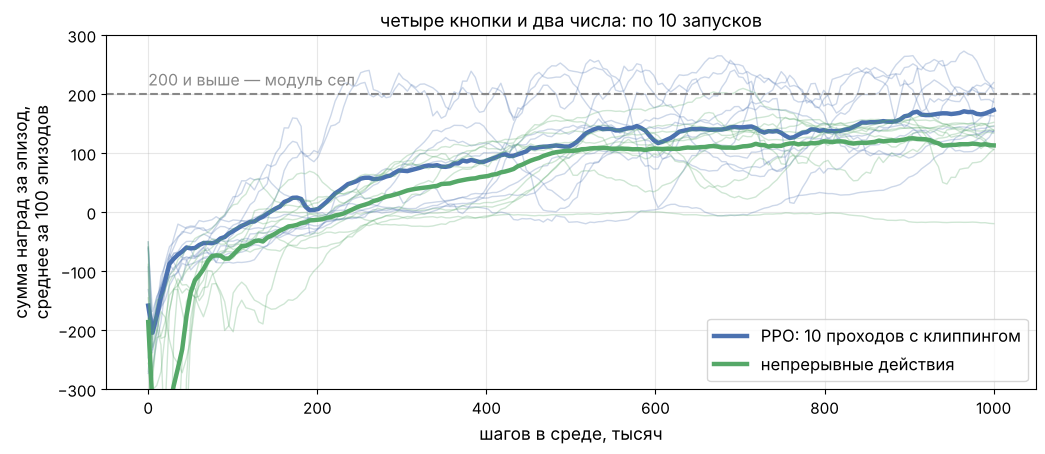

In [9]:
cont = [train_continuous(seed)[0] for seed in SEEDS] if TRAIN_LANDER else load_runs("cont")
print_runs("PPO, непрерывные действия", cont)
plot_lander_steps({"PPO: 10 проходов с клиппингом": runs["PPO: 10 проходов с клиппингом"],
                   "непрерывные действия": cont}, title="четыре кнопки и два числа: по 10 запусков")
plt.show()

За тот же миллион шагов непрерывный модуль выходит в среднем на 113 против 173 у четырёх кнопок: он учится лететь и зависать над площадкой, но садится реже (до среднего 200 дошёл 1 запуск из 10). Это ожидаемо: выбрать одно из четырёх действий проще, чем подобрать две тяги. Код при этом изменился в четырёх строках — среда, выход сети, разброс $\sigma$ и способ посчитать $\log \pi$.

Так выглядит посадка непрерывного модуля стратегией PPO:

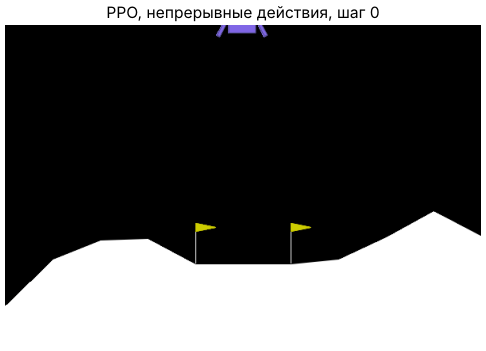

## 6. Итоги

1. **Проблема.** Вес действия посчитан для стратегии, сыгравшей кусок. После одного прохода стратегия почти та же, после десяти — у 28 % шагов вероятность меняется больше чем в 1.2 раза, и веса перестают её описывать.
2. **Мерка.** $\rho_t = \pi_\theta(a_t \mid s_t) / \pi_{\text{старая}}(a_t \mid s_t)$ — во сколько раз изменилась вероятность сыгранного действия.
3. **Клиппинг.** Слагаемое $\min(\rho_t A_t,\ \mathrm{clip}(\rho_t)A_t)$: за коридором $[0.8,\ 1.2]$ оно перестаёт расти, и градиент туда не тянет. С клиппингом за коридор выходят 1 % шагов вместо 28 %.
4. **PPO в четырёх шагах:** сыграть кусок и запомнить $\log \pi$ → посчитать преимущества → несколько раз пройти по куску с обрезанным $\rho$ → идти играть следующий кусок.
5. **Непрерывные действия.** Меняются только выход сети (средние вместо вероятностей) и $\log \pi$ (плотность вместо вероятности). На модуле с двумя тягами PPO выходит на 113 за миллион шагов.

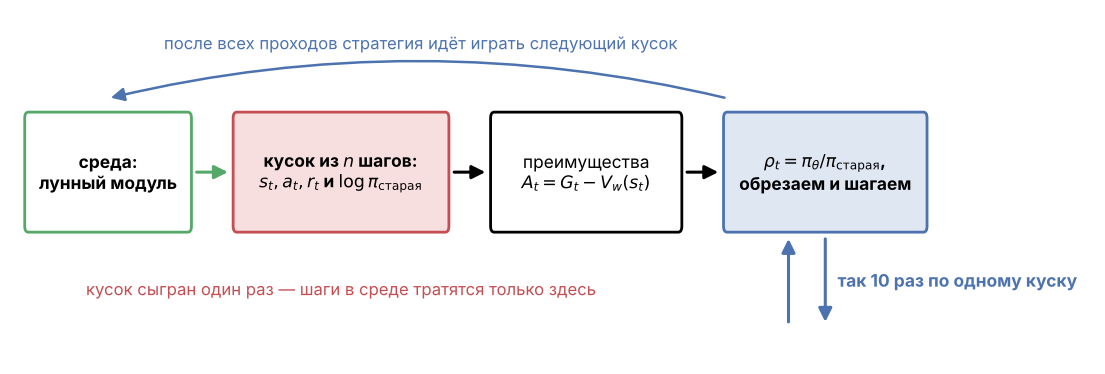

In [10]:
draw_ppo_scheme()
plt.show()

> **Простыми словами — вся лекция.** Данные собраны одной стратегией, а учим мы уже другую. Пока новая близка к старой, данные ещё годятся; клиппинг и следит за тем, чтобы она не ушла далеко — поэтому один и тот же кусок можно использовать много раз.

**Где это работает.** PPO — рабочая лошадка современного RL: на нём учат ходить роботов, играть ботов в Dota 2, управлять стратосферными шарами. На нём же устроено дообучение языковых моделей по оценкам людей (RLHF): вместо среды — диалог, вместо наград — оценка ответа, а чтобы модель не «уехала» от исходной, стоит то же ограничение на отличие стратегий. GRPO, которым учат рассуждающие модели, — упрощение PPO: критика заменяет среднее по нескольким ответам на один вопрос.

Словарь лекции: **отношение вероятностей (importance ratio), клиппинг (clipping), PPO, TRPO, гауссова стратегия**.

## Литература

* Schulman J. и др. *Proximal policy optimization algorithms*, 2017 — PPO. [arxiv.org/abs/1707.06347](https://arxiv.org/abs/1707.06347)
* Schulman J. и др. *Trust region policy optimization*. ICML, 2015 — TRPO, предшественник.
* Саттон Р., Барто Э. *Обучение с подкреплением*, 2-е изд., раздел 13.5 — актор-критик.
* [Учебник по машинному обучению ШАД, глава «Обучение с подкреплением»](https://education.yandex.ru/handbook/ml/article/obuchenie-s-podkrepleniem).

## На семинаре и дома

* Домашнее задание по лекциям 8–9 объявит преподаватель.